In [4]:
# Importing the libraries
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score
)
import seaborn as sns

In [5]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [6]:
PROJECT_DIR = Path.cwd()
DATASET_DIR = PROJECT_DIR / "fire_dataset"
CLASS_NAMES = ["no", "yes"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_DIR}. "
        "Create fire_dataset/no and fire_dataset/yes."
    )

records = []
for class_name in CLASS_NAMES:
    class_dir = DATASET_DIR / class_name
    if not class_dir.exists():
        raise FileNotFoundError(f"Missing class folder: {class_dir}")

    for image_path in class_dir.iterdir():
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            records.append({
                "filepath": str(image_path),
                "class_name": class_name,
                "label": 1 if class_name == "yes" else 0
            })

df = pd.DataFrame(records)
if df.empty:
    raise ValueError("No supported images found. Add JPG, JPEG, or PNG images.")

print("Total images:", len(df))
print(df["class_name"].value_counts())
display(df.head())

Total images: 999
class_name
yes    755
no     244
Name: count, dtype: int64


,filepath,class_name,label
0,C:\Users\anuru\OneDrive\文件\Desktop\Jupyter pro...,no,0
1,C:\Users\anuru\OneDrive\文件\Desktop\Jupyter pro...,no,0
2,C:\Users\anuru\OneDrive\文件\Desktop\Jupyter pro...,no,0
3,C:\Users\anuru\OneDrive\文件\Desktop\Jupyter pro...,no,0
4,C:\Users\anuru\OneDrive\文件\Desktop\Jupyter pro...,no,0


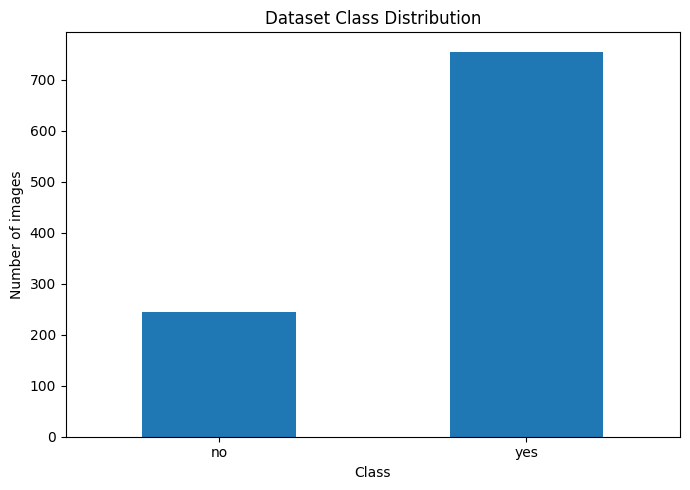

In [8]:
class_counts = df["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0)
ax = class_counts.plot(kind="bar", figsize=(7, 5), rot=0)
ax.set_title("Dataset Class Distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of images")
plt.tight_layout()
plt.show()

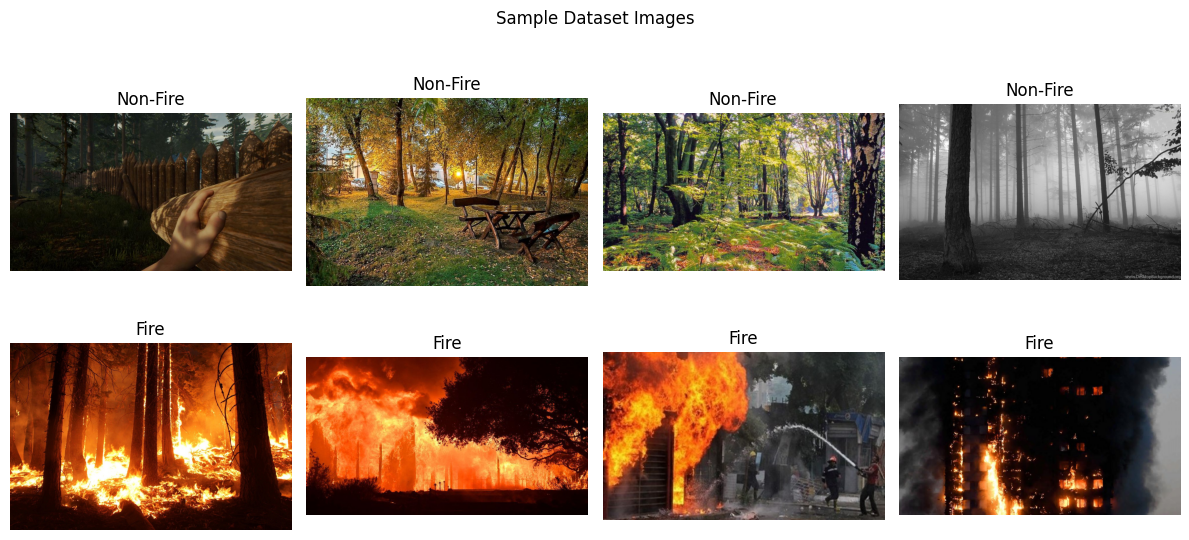

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for row, class_name in enumerate(CLASS_NAMES):
    samples = df[df["class_name"] == class_name].sample(
        n=min(4, (df["class_name"] == class_name).sum()),
        random_state=SEED
    )
    for col, ax in enumerate(axes[row]):
        ax.axis("off")
        if col < len(samples):
            image = tf.keras.utils.load_img(samples.iloc[col]["filepath"])
            ax.imshow(image)
            ax.set_title("Fire" if class_name == "yes" else "Non-Fire")
plt.suptitle("Sample Dataset Images")
plt.tight_layout()
plt.show()

In [32]:
train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    random_state=SEED,
    stratify=df["label"]
)

print(f"Training images: {len(train_df)}")
print(f"Validation images: {len(val_df)}")

Training images: 799
Validation images: 200


In [33]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(filepath, label):
    image = tf.io.read_file(filepath)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.cast(label, tf.float32)

def make_dataset(dataframe, training=False):
    paths = dataframe["filepath"].values
    labels = dataframe["label"].values
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe), seed=SEED,
            reshuffle_each_iteration=True
        )
    dataset = dataset.map(load_image, num_parallel_calls=AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return dataset

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)

In [34]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.10),
], name="data_augmentation")

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    data_augmentation,

    tf.keras.layers.Conv2D(32, 3, activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, 3, activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(1, activation="sigmoid")
], name="forest_fire_cnn")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()

Model: "forest_fire_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)       │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
MODEL_DIR = PROJECT_DIR / "artifacts"
MODEL_DIR.mkdir(exist_ok=True)
BEST_MODEL_PATH = MODEL_DIR / "best_forest_fire_model.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6
    )
]

EPOCHS = 15
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/15


C:\Users\anuru\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


25/25 ━━━━━━━━━━━━━━━━━━━━ 98s 3s/step - accuracy: 0.7559 - loss: 0.5331 - precision: 0.7592 - recall: 0.9917 - val_accuracy: 0.8500 - val_loss: 0.4044 - val_precision: 0.8758 - val_recall: 0.9338 - learning_rate: 0.0010
Epoch 2/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 109s 2s/step - accuracy: 0.8824 - loss: 0.2922 - precision: 0.9194 - recall: 0.9255 - val_accuracy: 0.9050 - val_loss: 0.2295 - val_precision: 0.9853 - val_recall: 0.8874 - learning_rate: 0.0010
Epoch 3/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 54s 2s/step - accuracy: 0.9474 - loss: 0.1775 - precision: 0.9607 - recall: 0.9702 - val_accuracy: 0.8750 - val_loss: 0.2566 - val_precision: 0.9773 - val_recall: 0.8543 - learning_rate: 0.0010
Epoch 4/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 117s 4s/step - accuracy: 0.9274 - loss: 0.1832 - precision: 0.9520 - recall: 0.9520 - val_accuracy: 0.9500 - val_loss: 0.1603 - val_precision: 0.9862 - val_recall: 0.9470 - learning_rate: 0.0010
Epoch 5/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 107s 4s/step - accuracy: 0.9537 - loss: 0.1

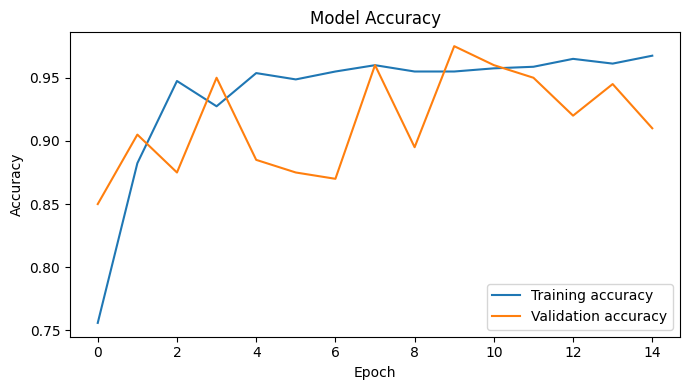

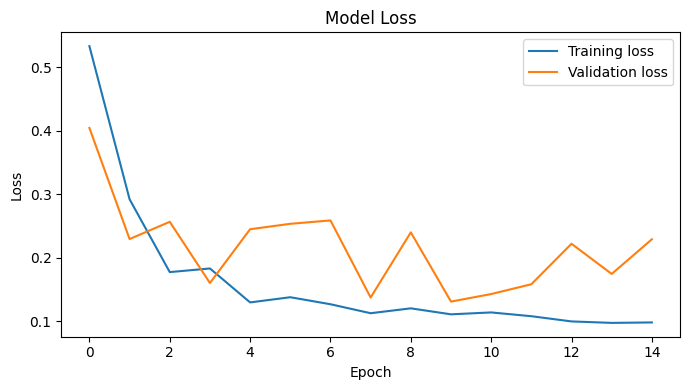

In [36]:
history_df = pd.DataFrame(history.history)

plt.figure(figsize=(7, 4))
plt.plot(history_df["accuracy"], label="Training accuracy")
plt.plot(history_df["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history_df["loss"], label="Training loss")
plt.plot(history_df["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model Loss")
plt.legend()
plt.tight_layout()
plt.show()

In [37]:
# Load the best checkpoint saved during training
best_model = tf.keras.models.load_model(BEST_MODEL_PATH)

y_true = np.concatenate([labels.numpy() for _, labels in val_ds]).astype(int)
y_prob = best_model.predict(val_ds, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(
    y_true, y_pred, labels=[0, 1],
    target_names=["Non-Fire", "Fire"],
    zero_division=0
))

metrics = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision": precision_score(y_true, y_pred, zero_division=0),
    "Recall": recall_score(y_true, y_pred, zero_division=0),
    "F1-score": f1_score(y_true, y_pred, zero_division=0)
}
for metric_name, value in metrics.items():
    print(f"{metric_name}: {value:.4f}")

              precision    recall  f1-score   support

    Non-Fire       0.92      0.98      0.95        49
        Fire       0.99      0.97      0.98       151

    accuracy                           0.97       200
   macro avg       0.96      0.98      0.97       200
weighted avg       0.98      0.97      0.98       200

Accuracy: 0.9750
Precision: 0.9932
Recall: 0.9735
F1-score: 0.9833


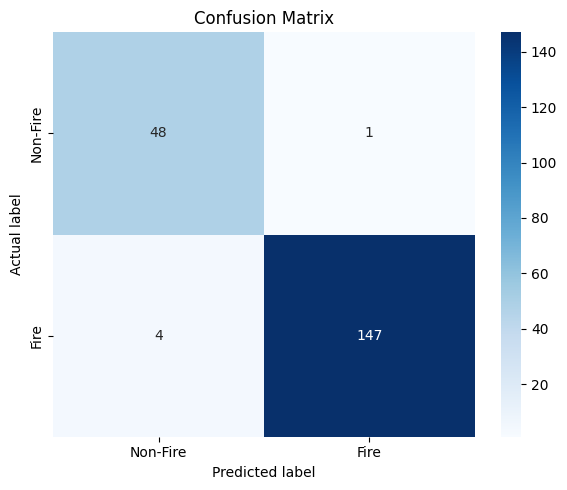

In [38]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Non-Fire", "Fire"],
    yticklabels=["Non-Fire", "Fire"]
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [39]:
FINAL_MODEL_PATH = MODEL_DIR / "forest_fire_detection.keras"
best_model.save(FINAL_MODEL_PATH)
print("Model saved to:", FINAL_MODEL_PATH)

Model saved to: C:\Users\anuru\OneDrive\文件\Desktop\Jupyter projects\Forest-Fire-Detection\artifacts\forest_fire_detection.keras


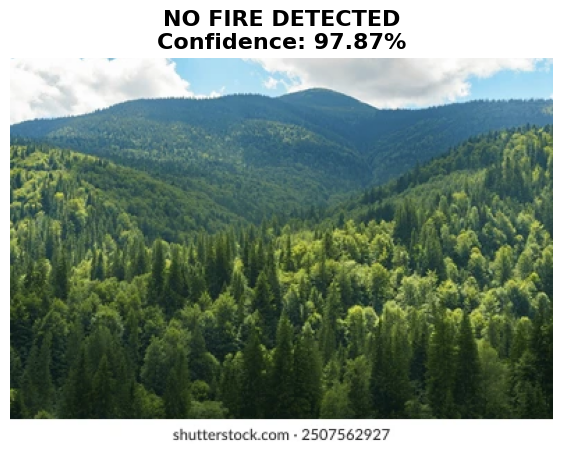

Prediction: NO FIRE DETECTED
Confidence: 97.87%


('NO FIRE DETECTED', np.float32(97.86975))

In [46]:
def predict_forest_fire(image_path, trained_model=best_model):

    image_path = Path(image_path)

    if not image_path.exists():
        raise FileNotFoundError(f"Image not found: {image_path}")

    # Load and preprocess image
    image = tf.keras.utils.load_img(
        image_path,
        target_size=(224, 224)
    )

    image_array = tf.keras.utils.img_to_array(image)
    image_array = image_array / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    # Predict
    prediction = trained_model.predict(image_array, verbose=0)[0][0]

    if prediction >= 0.5:
        result = "FIRE DETECTED"
        confidence = prediction * 100
    else:
        result = "NO FIRE DETECTED"
        confidence = (1 - prediction) * 100

    # Display image and prediction
    plt.figure(figsize=(7, 6))
    plt.imshow(tf.keras.utils.load_img(image_path))
    plt.axis("off")

    plt.title(
        f"{result}\nConfidence: {confidence:.2f}%",
        fontsize=16,
        fontweight="bold"
    )

    plt.show()

    print("Prediction:", result)
    print(f"Confidence: {confidence:.2f}%")

    return result, confidence

TEST_IMAGE = PROJECT_DIR / "test_images" / "forest-5.webp"

predict_forest_fire(TEST_IMAGE)